# Classificando Flores com o Dataset Iris

Problema

Você foi contratado por uma empresa que desenvolve soluções para laboratórios de botânica.

O laboratório recebe centenas de flores diariamente e deseja automatizar a identificação das espécies.

Seu trabalho é desenvolver um modelo de Machine Learning capaz de identificar automaticamente a espécie de uma flor utilizando suas medidas.

Ao final do projeto, o modelo treinado deverá ser salvo para ser utilizado posteriormente em uma aplicação web.

Objetivos

Ao concluir este projeto você será capaz de:
* Explorar um dataset real;
* Compreender as variáveis do problema;
* Treinar um modelo utilizando Scikit-learn;
* Avaliar o desempenho do modelo;
* Salvar o modelo treinado;
* Utilizar o modelo posteriormente em um sistema desenvolvido com Streamlit.

# Conhecendo o Dataset

O dataset Iris está disponível no próprio Scikit-learn.

Carregue o conjunto de dados.

In [1]:
from sklearn.datasets import load_iris

iris = load_iris()

Transforme o dataset em um DataFrame do Pandas.

O DataFrame deverá possuir as colunas:

* sepal length
* sepal width
* petal length
* petal width
* espécie

In [2]:
import pandas as pd

# Crie um DataFrame a partir dos dados da íris com os nomes das características como colunas.
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Adicione a coluna (espécie)
df_iris['espécie'] = iris.target

# Mapeie o alvo numérico para os nomes reais das espécies para melhor legibilidade.
df_iris['espécie'] = df_iris['espécie'].apply(lambda x: iris.target_names[x])

# Exibir as primeiras linhas do DataFrame
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),espécie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Responda:

* Quantas linhas existem?
* Quantas colunas?
* Existem valores ausentes?
* Existem valores duplicados?

Utilize:

* head()
* tail()
* info()
* describe()
* isnull().sum()
* duplicated().sum()

In [5]:
print("--- Primeiras 5 linhas (df_iris.head()) ---")
print(df_iris.head())
print("\n--- Últimas 5 linhas (df_iris.tail()) ---")
print(df_iris.tail())
print("\n--- Informações gerais (df_iris.info()) ---")
df_iris.info()
print("\n--- Descrição estatística (df_iris.describe()) ---")
print(df_iris.describe())
print("\n--- Contagem de valores ausentes por coluna (df_iris.isnull().sum()) ---")
print(df_iris.isnull().sum())
print("\n--- Total de linhas duplicadas (df_iris.duplicated().sum()) ---")
print(df_iris.duplicated().sum())

--- Primeiras 5 linhas (df_iris.head()) ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  espécie  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

--- Últimas 5 linhas (df_iris.tail()) ---
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4  



---



# Entendendo os Dados

Responda às perguntas:
1. Qual é a variável alvo (target) do problema?

 Dica 1: Observe as colunas do DataFrame.

 Dica 2: Pense na pergunta que o modelo deverá responder.

 Dica 3: Utilize um dos comandos abaixo.

df.columns

ou

df.head()






In [10]:
df_iris.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'espécie'],
      dtype='object')


2. Quantas espécies diferentes existem no dataset?

 Dica 1: Descubra quais valores aparecem na coluna especie.

 Dica 2: Existe uma função do Pandas que mostra apenas os valores únicos:
 df["especie"].unique()

In [13]:
print(f"Existem {df_iris['espécie'].nunique()} espécies diferentes no dataset.")

Existem 3 espécies diferentes no dataset.


3. Quantas flores existem de cada espécie?

 Dica 1: Você precisa contar quantas vezes cada espécie aparece.

 Dica 2: O Pandas possui uma função específica para contagem de categorias.

Experimente:

df["especie"].value_counts()

In [16]:
print("Quantidade de flores por espécie:")
print(df_iris['espécie'].value_counts())

Quantidade de flores por espécie:
espécie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# Visualização

Construa os seguintes gráficos:

* Histograma das pétalas;
* Histograma das sépalas;
* Gráfico de dispersão entre:

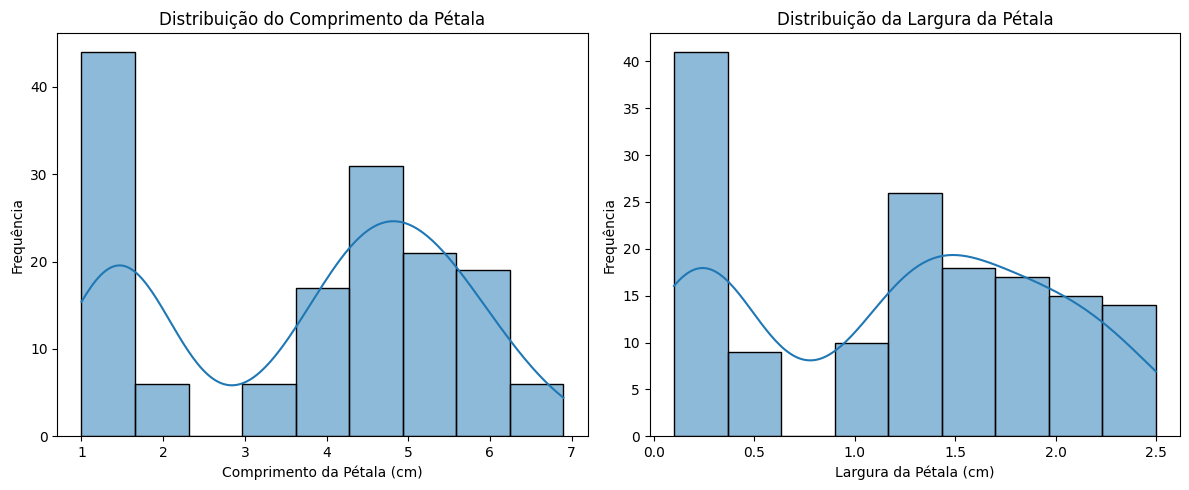

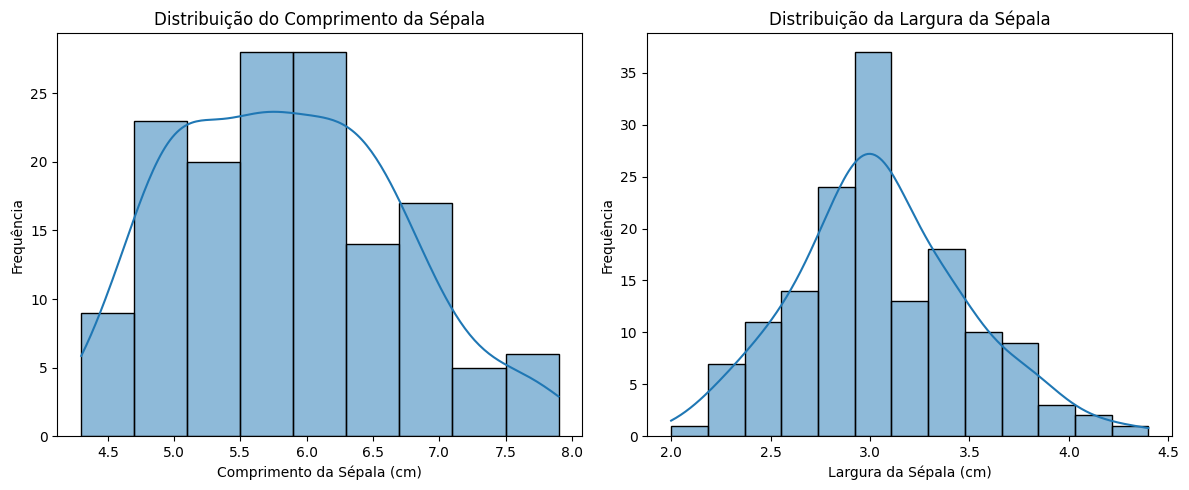

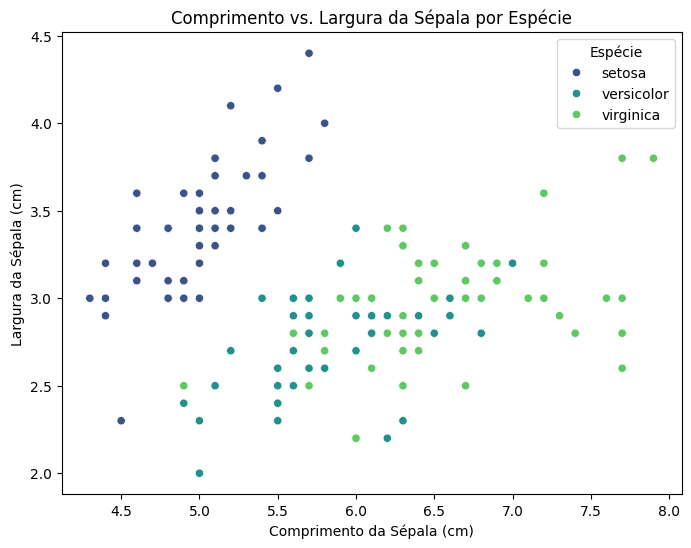

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma das pétalas
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_iris['petal length (cm)'], kde=True)
plt.title('Distribuição do Comprimento da Pétala')
plt.xlabel('Comprimento da Pétala (cm)')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_iris['petal width (cm)'], kde=True)
plt.title('Distribuição da Largura da Pétala')
plt.xlabel('Largura da Pétala (cm)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

# Histograma das sépalas
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_iris['sepal length (cm)'], kde=True)
plt.title('Distribuição do Comprimento da Sépala')
plt.xlabel('Comprimento da Sépala (cm)')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df_iris['sepal width (cm)'], kde=True)
plt.title('Distribuição da Largura da Sépala')
plt.xlabel('Largura da Sépala (cm)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

# Gráfico de dispersão entre: (Ainda não especificado quais variáveis, vou usar um par comum)
# Por exemplo, Comprimento da Sépala vs. Largura da Sépala, colorido por espécie
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_iris, x='sepal length (cm)', y='sepal width (cm)', hue='espécie', palette='viridis')
plt.title('Comprimento vs. Largura da Sépala por Espécie')
plt.xlabel('Comprimento da Sépala (cm)')
plt.ylabel('Largura da Sépala (cm)')
plt.legend(title='Espécie')
plt.show()

# Preparando os Dados

Crie:

X

contendo:

* sepal length
* sepal width
* petal length
* petal width

In [17]:
X = df_iris[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']]

Crie:

y

contendo:

espécie

y = df_iris['espécie']

In [18]:
y = df_iris['espécie']

# Separando Treino e Teste

Utilize:

train_test_split()

Perguntas:

* Quantos registros ficaram para treino?
* Quantos registros ficaram para teste?

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Registros para treino: {len(X_train)}")
print(f"Registros para teste: {len(X_test)}")

Registros para treino: 105
Registros para teste: 45


# Treinando o Modelo

Utilize:

* KNeighborsClassifier


* from sklearn.neighbors import KNeighborsClassifier

# Inicialize o modelo K-Nearest Neighbors
* knn = KNeighborsClassifier(n_neighbors=3) # Você pode ajustar o número de vizinhos (n_neighbors)

# Treine o modelo usando os dados de treinamento
* knn.fit(X_train, y_train)


In [20]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)



---



# Avaliando

Agora é hora de descobrir se o modelo treinado conseguiu classificar corretamente as flores.


Mostre a Accuracy do modelo.

Pergunta:

1. Qual foi a taxa de acertos do modelo?

 Dica 1: A Accuracy representa a porcentagem de previsões corretas.

 Dica 2: Você pode utilizar uma função da biblioteca sklearn.metrics.

 Experimente:

* from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

ou

* modelo.score(X_test, y_test)

In [21]:
from sklearn.metrics import accuracy_score

# Faça previsões no conjunto de teste
y_pred = knn.predict(X_test)

# Calcule a acurácia
accuracy = accuracy_score(y_test, y_pred)

print(f"Acurácia do modelo: {accuracy:.2f}")

Acurácia do modelo: 1.00


Mostre a Matriz de Confusão.

Pergunta:

2. Quantas flores foram classificadas corretamente?

 Dica 1: Utilize a função:

confusion_matrix()

Dica 2: Observe a diagonal principal da matriz.

Os valores da diagonal representam as classificações corretas.

Experimente:

from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred)

In [24]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Gere a matriz de confusão
cm = confusion_matrix(y_test, y_pred)

print("Matriz de Confusão:")
print(cm)

# Calcule o número de classificações corretas (soma dos elementos da diagonal)
correct_predictions = np.trace(cm)
print(f"\nNúmero de flores classificadas corretamente: {correct_predictions}")

Matriz de Confusão:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Número de flores classificadas corretamente: 45


Observe novamente a Matriz de Confusão.

Pergunta:

3. Em quais espécies ocorreram erros?

 Dica 1: Os erros aparecem fora da diagonal principal.

 Dica 2: Se um valor estiver na linha da Classe 0 e coluna da Classe 1, significa que uma flor da Classe 0 foi prevista como Classe 1.

 Dica 3: Compare esses erros com os nomes das espécies utilizando:

iris.target_names

In [25]:
print("Matriz de Confusão:")
print(cm)

print("\nNomes das espécies (iris.target_names):")
print(iris.target_names)

print("\nDe acordo com a Matriz de Confusão, não houve erros de classificação. Todos os valores fora da diagonal principal são zero, indicando que o modelo previu corretamente todas as flores para suas respectivas espécies.")

Matriz de Confusão:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Nomes das espécies (iris.target_names):
['setosa' 'versicolor' 'virginica']

De acordo com a Matriz de Confusão, não houve erros de classificação. Todos os valores fora da diagonal principal são zero, indicando que o modelo previu corretamente todas as flores para suas respectivas espécies.


Mostre o Classification Report.

Pergunta:

 4. Qual classe apresentou melhor desempenho?

 Dica 1: Utilize:

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

 Dica 2: Observe as colunas:

* Precision
* Recall
* F1-score

In [26]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



# Analise os resultados.

Responda:

1. O modelo apresentou uma boa Accuracy?
2. Houve muitas classificações incorretas?
3. Qual espécie foi mais fácil de identificar?
4. Qual espécie apresentou mais erros?

 Dica: Compare a Accuracy com a Matriz de Confusão. Uma Accuracy alta normalmente significa poucos erros, mas a matriz mostra onde esses erros aconteceram.



---



# Fazendo Novas Previsões

O laboratório recebeu três novas flores.

## Flor A
##Característica:
* Sepal Length
* Sepal Width
* Petal Length
* Petal Width
## Valor:
* 5.1
* 3.5
* 1.4
* 0.2

Qual espécie foi prevista?

In [30]:
import numpy as np

# Flor A
flor_a = np.array([[5.1, 3.5, 1.4, 0.2]])
prediction_a = knn.predict(flor_a)
print(f"Previsão para Flor A: {prediction_a[0]} (Original: setosa)")

Previsão para Flor A: setosa (Original: setosa)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(




---



# Flor B

##Característica:
* Sepal Length
* Sepal Width
* Petal Length
* Petal Width
## Valor:
* 6.2
* 2.9
* 4.3
* 1.3

Qual espécie foi prevista?

In [31]:
# Flor B
flor_b = np.array([[6.2, 2.9, 4.3, 1.3]])
prediction_b = knn.predict(flor_b)
print(f"Previsão para Flor B: {prediction_b[0]} (Original: versicolor)")


Previsão para Flor B: versicolor (Original: versicolor)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(




---



# Flor C

##Característica:
* Sepal Length
* Sepal Width
* Petal Length
* Petal Width
## Valor:
* 6.9
* 3.1
* 5.4
* 2.1

Qual espécie foi prevista?

In [33]:
# Flor C
flor_c = np.array([[6.9, 3.1, 5.4, 2.1]])
prediction_c = knn.predict(flor_c)
print(f"Previsão para Flor C: {prediction_c[0]} (Original: virginica)")

Previsão para Flor C: virginica (Original: virginica)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(




---



# Salvando o Modelo

In [27]:
import joblib

# Executar essa linha após o treinamento do modelo.
joblib.dump(knn, 'iris_model.pkl')

['iris_model.pkl']

In [28]:
import joblib

# Salve os nomes das espécies:
joblib.dump(iris.target_names, 'iris_classes.pkl')

print("Species names saved to 'iris_classes.pkl'")

Species names saved to 'iris_classes.pkl'
